# Assignment 3 · Part B — DashMart: How Long Will My Order Take?
KNN regression on the raw order export. Every imputer and scaler lives inside a Pipeline, and `random_state = 42` everywhere.

In [1]:
import re, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
RS = 42
PATH = 'dashmart_delivery_times_raw.csv'

## Q1 — Load as text; find the raw formats

In [2]:
raw = pd.read_csv(PATH, dtype=str, keep_default_na=False)
print('Shape:', raw.shape); print('Columns:', list(raw.columns))
def formats(s):                      # replace digits by 9 to reveal the "shape" of each value
    return s.str.replace(r'\d+', '9', regex=True).value_counts().to_dict()
for c in ['order_hour', 'distance_km', 'delivery_minutes']:
    print(f'\n{c} formats:', formats(raw[c]))
    print('   examples:', raw[c].drop_duplicates().sample(8, random_state=RS).tolist())

Shape: (2430, 11)
Columns: ['order_id', 'store', 'order_hour', 'distance_km', 'items', 'order_value_rs', 'store_queue', 'raining', 'rider_experience_months', 'drop_floor', 'delivery_minutes']

order_hour formats: {'9': 1766, '9:9': 313, '9 PM': 250, '9 AM': 101}
   examples: ['14:00', '14', '10 AM', '9', '3 PM', '2 AM', '16', '11:00']

distance_km formats: {'9.9': 1638, '9.9 km': 410, '9 m': 382}
   examples: ['1.37', '2.94', '1.12 km', '2.64', '0.84', '2.67', '2.32', '0.43']

delivery_minutes formats: {'9.9': 2000, '9:9:9': 275, '9.9 min': 153, '-9.9': 2}
   examples: ['0:14:30', '13.8 min', '19.3', '0:15:30', '0:15:18', '20.4', '23.6', '0:14:18']


**Q1 — answer / interpretation:** The file has 2,430 rows × 11 columns.

- **order_hour** comes in 4 formats: `20`, `20:00`, `8 PM`, `8 AM`.
- **distance_km** comes in 3: plain kilometres, `1.4 km`, and metres (`850 m`).
- **delivery_minutes** comes in 4: plain, `14.6 min`, `0:14:36` (h:mm:ss), and negatives.

Each one needs its own parser.

## Q2 — Clean store; order_hour → integer 0–23

In [3]:
df = raw.copy()
df['store'] = 'DM-' + (df['store'].str.strip().str.lower()
                       .str.replace(r'^dm[\s\-]*', '', regex=True).str.title())
print('store:', df['store'].value_counts().to_dict())

def parse_hour(x):
    x = x.strip().upper()
    m = re.fullmatch(r'(\d{1,2})\s*(AM|PM)', x)
    if m:
        h, ap = int(m.group(1)), m.group(2)
        if h == 12: h = 0              # 12 AM = 00:00, 12 PM = 12:00
        return h + 12 if ap == 'PM' else h
    if ':' in x: return int(x.split(':')[0])
    return int(x)

df['order_hour'] = raw['order_hour'].map(parse_hour)
demo = ['8 PM', '12 AM', '12 PM', '1 AM', '11 PM', '20:00', '9']
print(pd.DataFrame({'raw': demo, 'parsed': [parse_hour(d) for d in demo]}).to_string(index=False))
assert df['order_hour'].between(0, 23).all()
print('order_hour range:', df['order_hour'].min(), '–', df['order_hour'].max())

store: {'DM-Nerul': 638, 'DM-Vashi': 624, 'DM-Kharghar': 595, 'DM-Panvel': 573}
  raw  parsed
 8 PM      20
12 AM       0
12 PM      12
 1 AM       1
11 PM      23
20:00      20
    9       9
order_hour range: 0 – 23


**Q2 — answer / interpretation:** Store went from **16 spellings to 4** (DM-Kharghar, DM-Nerul, DM-Panvel, DM-Vashi). For AM/PM hours, 12 AM → 0, 12 PM → 12, and any other PM hour gets +12 (8 PM → 20). `20:00` takes the part before the colon. All values now fall in 0–23.

## Q3 — distance_km → kilometres

In [4]:
def parse_km(x):
    x = x.strip().lower()
    if x.endswith('km'): return float(x[:-2])
    if x.endswith('m'):  return float(x[:-1]) / 1000
    return float(x)
df['distance_km'] = raw['distance_km'].map(parse_km)
ex = raw['distance_km'][raw['distance_km'].str.contains('m')].drop_duplicates().sample(5, random_state=RS).index
print(pd.DataFrame({'before': raw.loc[ex, 'distance_km'], 'after_km': df.loc[ex, 'distance_km']}))
print(df['distance_km'].describe().round(2))

       before  after_km
101   0.38 km      0.38
815   2.13 km      2.13
1715    270 m      0.27
1913  1.87 km      1.87
447   1.24 km      1.24
count    2430.00
mean        1.30
std         0.87
min         0.20
25%         0.65
50%         1.10
75%         1.73
max         5.00
Name: distance_km, dtype: float64


**Q3 — answer / interpretation:** 382 values were in metres and are now divided by 1,000 (e.g. `270 m` → 0.27). The "km" suffix is simply stripped. Distances now range from 0.2 to 5 km, which is plausible for a dark store.

## Q4 — delivery_minutes → decimal minutes; drop impossible values

In [5]:
def parse_min(x):
    x = x.strip().lower().replace('min', '').strip()
    if ':' in x:
        h, m, s = map(int, x.split(':')); return h * 60 + m + s / 60
    return float(x)
df['delivery_minutes'] = raw['delivery_minutes'].map(parse_min)
hx = raw.index[raw['delivery_minutes'].str.contains(':')][:3].tolist() + raw.index[raw['delivery_minutes'].str.contains('min')][:2].tolist()
print(pd.DataFrame({'before': raw.loc[hx, 'delivery_minutes'], 'after': df.loc[hx, 'delivery_minutes'].round(2)}))

print('\nSorted extremes:', np.sort(df['delivery_minutes'])[:5], '…', np.sort(df['delivery_minutes'])[-10:])
impossible = (df['delivery_minutes'] <= 0) | (df['delivery_minutes'] > 120)
print('Impossible rows:', impossible.sum(), df.loc[impossible, 'delivery_minutes'].round(1).tolist())
df = df[~impossible].copy()
print('Rows left:', len(df))

      before  after
28   0:06:12    6.2
51   0:13:42   13.7
73   0:13:24   13.4
12  14.4 min   14.4
17  18.4 min   18.4

Sorted extremes: [-5. -5.  0.  5.  5.] … [  31.9   32.4   33.    34.7  412.   987.5  987.5 1440.  1440.  1440. ]
Impossible rows: 9 [-5.0, -5.0, 0.0, 1440.0, 987.5, 1440.0, 412.0, 987.5, 1440.0]
Rows left: 2421


**Q4 — answer / interpretation:** `0:14:36` becomes 14.6 minutes and "min" is stripped.

**Rule: keep 0 < minutes ≤ 120.** There is a clear gap in the data: the largest believable value is 34.7 min, and the next is 412. That rule drops **9 rows**: −5, −5, 0, 412, 987.5 ×2 and 1,440 ×3 (exactly 24 h).

**Why drop rather than fix:** we don't know the true time for these orders. Negatives and zeros are timestamp errors. The huge values are cancelled-then-reopened orders, so they measure how long an order waited to be reopened, not a delivery. Any "fix" would be made-up data, and keeping them would wreck both the MAE and every neighbour average they appear in.

## Q5 — raining, order value, rider experience; remove duplicates

In [6]:
r = df['raining'].str.strip().str.upper()
df['raining'] = r.map({'Y': 1, 'YES': 1, '1': 1, 'TRUE': 1, 'N': 0, 'NO': 0, '0': 0, 'FALSE': 0})
assert df['raining'].notna().all()
df['order_value_rs'] = pd.to_numeric(df['order_value_rs'].str.replace(r'[₹,\s]', '', regex=True))
rx = df['rider_experience_months'].str.strip().str.lower().replace({'new joiner': '0'})
df['rider_experience_months'] = pd.to_numeric(rx.replace({'': np.nan, 'na': np.nan, '?': np.nan}), errors='coerce')
df['store_queue'] = pd.to_numeric(df['store_queue'].replace({'': np.nan, '?': np.nan}), errors='coerce')
for c in ['items', 'drop_floor']: df[c] = pd.to_numeric(df[c])

before = len(df)
print('Exact duplicate rows:', df.duplicated().sum(), '| duplicated order_ids:', df['order_id'].duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print(f'Rows before: {before}  after: {len(df)}')
print(df.dtypes)

Exact duplicate rows: 30 | duplicated order_ids: 30
Rows before: 2421  after: 2391
order_id                       str
store                          str
order_hour                   int64
distance_km                float64
items                        int64
order_value_rs             float64
store_queue                float64
raining                      int64
rider_experience_months    float64
drop_floor                   int64
delivery_minutes           float64
dtype: object


**Q5 — answer / interpretation:** Raining is now 0/1. The ₹ symbol and commas are stripped from order value. "new joiner" → 0 months, and blank/NA → NaN. I removed **30 exact duplicates (2,421 → 2,391)**. They match the 30 repeated order_ids exactly, so they were re-exports.

## Q6 — Missing values; save cleaned file

In [7]:
print(df.isna().sum())
df.to_csv('dashmart_clean.csv', index=False)
print('Saved dashmart_clean.csv', df.shape)

order_id                    0
store                       0
order_hour                  0
distance_km                 0
items                       0
order_value_rs              0
store_queue                40
raining                     0
rider_experience_months    43
drop_floor                  0
delivery_minutes            0
dtype: int64
Saved dashmart_clean.csv (2391, 11)


**Q6 — answer / interpretation:** Only **store_queue (40)** and **rider_experience_months (43)** have gaps, about 2 % each. I'll use **median imputation inside the pipeline**, fitted on training rows only. Both are skewed counts, so the median is safer than the mean, and at 2 % missing a more complex imputer isn't worth it.

## Q7 — Describe delivery_minutes

count    2391.00
mean       14.70
std         4.57
min         5.00
25%        11.50
50%        14.10
75%        17.30
max        34.70
Name: delivery_minutes, dtype: float64
Median 14.1 min, mean 14.7 min
Share of orders later than 15 min: 41.7%
Median late order is 3.1 min past the promise


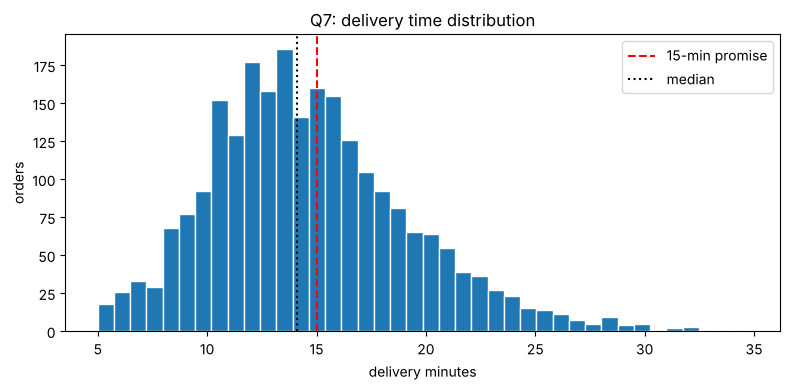

In [8]:
y_all = df['delivery_minutes']
print(y_all.describe().round(2))
print(f'Median {y_all.median():.1f} min, mean {y_all.mean():.1f} min')
print(f'Share of orders later than 15 min: {(y_all > 15).mean():.1%}')
print(f'Median late order is {(y_all[y_all > 15] - 15).median():.1f} min past the promise')
plt.figure(figsize=(8, 4)); plt.hist(y_all, bins=40, edgecolor='white')
plt.axvline(15, color='red', ls='--', label='15-min promise'); plt.axvline(y_all.median(), color='black', ls=':', label='median')
plt.xlabel('delivery minutes'); plt.ylabel('orders'); plt.title('Q7: delivery time distribution'); plt.legend()
plt.tight_layout(); plt.savefig('partB_q7_hist.png', dpi=120); plt.show()

**Q7 — answer / interpretation:** Median **14.1 min**, mean **14.7 min** (slight right tail, max 34.7). The typical order actually *beats* the 15-minute promise by about 1 minute, yet **41.7 % of orders break it**, and a typical late order arrives about 3 minutes late. The problem isn't the average order. A single flat promise ignores the spread from 5 to 35 minutes.

## Q8 — 80/20 split and the median baseline

In [9]:
FEAT = ['distance_km', 'items', 'order_value_rs', 'store_queue', 'raining',
        'rider_experience_months', 'drop_floor', 'order_hour']
df['hour_sin'] = np.sin(2 * np.pi * df['order_hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['order_hour'] / 24)
X = df.drop(columns='delivery_minutes'); y = df['delivery_minutes']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS)
print('train', X_train.shape, 'test', X_test.shape)

def scores(yt, yp):
    return dict(MAE=mean_absolute_error(yt, yp), RMSE=float(np.sqrt(mean_squared_error(yt, yp))), R2=r2_score(yt, yp))
base = scores(y_test, np.full(len(y_test), y_train.median()))
print(f'Training median = {y_train.median():.1f} min'); print({k: round(v, 3) for k, v in base.items()})

train (1912, 12) test (479, 12)
Training median = 14.1 min
{'MAE': 3.519, 'RMSE': 4.526, 'R2': -0.028}


**Q8 — answer / interpretation:** Predicting the training median (14.1 min) for every order is off by **3.52 minutes** on average (MAE). Every model has to beat that.

## Q9 — KNN regressor (k = 7), NO scaling

In [10]:
raw_knn = make_pipeline(SimpleImputer(strategy='median'), KNeighborsRegressor(n_neighbors=7)).fit(X_train[FEAT], y_train)
s_raw = scores(y_test, raw_knn.predict(X_test[FEAT]))
print(pd.DataFrame({'median baseline': base, 'raw KNN k=7': s_raw}).round(3))

      median baseline  raw KNN k=7
MAE             3.519        3.721
RMSE            4.526        4.670
R2             -0.028       -0.095


**Q9 — answer / interpretation:** Unscaled KNN does **worse than the median baseline**: MAE 3.72 vs 3.52, and R² = −0.095. A negative R² means the model's predictions are worse than just quoting the average time to everyone. An R² near zero means it explains none of why one order takes longer than another.

## Q10 — StandardScaler vs MinMaxScaler

In [11]:
std_knn = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsRegressor(n_neighbors=7)).fit(X_train[FEAT], y_train)
mm_knn  = make_pipeline(SimpleImputer(strategy='median'), MinMaxScaler(),  KNeighborsRegressor(n_neighbors=7)).fit(X_train[FEAT], y_train)
s_std = scores(y_test, std_knn.predict(X_test[FEAT])); s_mm = scores(y_test, mm_knn.predict(X_test[FEAT]))
print(pd.DataFrame({'raw': s_raw, 'standard': s_std, 'min-max': s_mm}).round(3))
print('\nTraining std per feature:'); print(X_train[FEAT].std().round(2).sort_values(ascending=False).to_string())
print('\nCorrelation with delivery_minutes:'); print(X_train[FEAT].corrwith(y_train).round(3).sort_values().to_string())
val_only = make_pipeline(SimpleImputer(strategy='median'), KNeighborsRegressor(n_neighbors=7)).fit(X_train[['order_value_rs']], y_train)
print('\nRaw KNN vs value-only KNN, corr of predictions:',
      round(np.corrcoef(raw_knn.predict(X_test[FEAT]), val_only.predict(X_test[['order_value_rs']]))[0, 1], 3))

        raw  standard  min-max
MAE   3.721     1.726    1.773
RMSE  4.670     2.165    2.216
R2   -0.095     0.765    0.754

Training std per feature:
order_value_rs             320.02
drop_floor                   8.73
rider_experience_months      8.16
order_hour                   5.46
store_queue                  3.47
items                        2.41
distance_km                  0.87
raining                      0.41

Correlation with delivery_minutes:
rider_experience_months   -0.078
order_value_rs             0.036
order_hour                 0.067
items                      0.067
drop_floor                 0.119
raining                    0.309
store_queue                0.329
distance_km                0.791

Raw KNN vs value-only KNN, corr of predictions: 0.3


**Q10 — answer / interpretation:** Scaling **halves the error**: MAE 3.72 → 1.73 and R² −0.10 → 0.77. StandardScaler edges out MinMaxScaler (1.73 vs 1.77), because min-max squeezes most values together when a few large baskets set the range.

**order_value_rs hijacked the raw model.** Its standard deviation is ₹320, against less than 9 for every other column, so "similar order" meant "similar basket price". Yet basket value has almost no link to delivery time (correlation 0.04): the rider carries the same bag the same distance whether it holds ₹300 or ₹1,500, and whatever packing effect exists is already captured by `items`. Meanwhile **distance_km, the strongest predictor (correlation 0.79), had a std of 0.87** and was effectively ignored.

## Q11 — MAE vs RMSE

In [12]:
err = y_test - std_knn.predict(X_test[FEAT])
print(f'MAE {err.abs().mean():.2f}  RMSE {np.sqrt((err**2).mean()):.2f}  — share of orders off by >5 min: {(err.abs() > 5).mean():.1%}')

MAE 1.73  RMSE 2.17  — share of orders off by >5 min: 1.9%


**Q11 — answer / interpretation:** *For the operations head:* "MAE is how many minutes we're off on a typical order. RMSE punishes the big misses more heavily, so it rises fast if we're occasionally 10 minutes off." The **"typical error under 2.5 min" target is MAE**. Here MAE is 1.73 and RMSE 2.17. They are close, and only 1.9 % of orders are off by more than 5 minutes, so big misses are rare.

## Q12 — Choose k with 5-fold CV (MAE)

1     2.254
2     1.928
3     1.833
5     1.763
7     1.742
9     1.749
11    1.749
15    1.793
21    1.823
31    1.891
51    1.985
Best k: 7


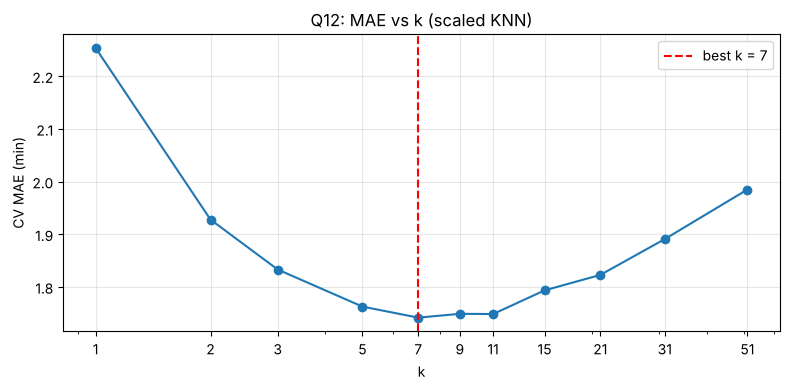

In [13]:
cv = KFold(n_splits=5, shuffle=True, random_state=RS)
ks = [1, 2, 3, 5, 7, 9, 11, 15, 21, 31, 51]
cv_mae = [-cross_val_score(make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsRegressor(n_neighbors=k)),
                           X_train[FEAT], y_train, cv=cv, scoring='neg_mean_absolute_error').mean() for k in ks]
best_k = ks[int(np.argmin(cv_mae))]
print(pd.Series(cv_mae, index=ks, name='CV MAE').round(3).to_string()); print('Best k:', best_k)
plt.figure(figsize=(8, 4)); plt.plot(ks, cv_mae, 'o-'); plt.axvline(best_k, color='red', ls='--', label=f'best k = {best_k}')
plt.xscale('log'); plt.xticks(ks, ks); plt.xlabel('k'); plt.ylabel('CV MAE (min)'); plt.title('Q12: MAE vs k (scaled KNN)')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig('partB_q12_k_curve.png', dpi=120); plt.show()

**Q12 — answer / interpretation:** **Best k = 7** (CV MAE 1.742), with k from 5 to 11 essentially tied.

- **k = 1 (MAE 2.25):** it copies one past order's time, including that order's random luck (a lift that was out, a gate guard). That is high variance.
- **k = 51 (MAE 1.99):** it averages over orders at very different distances and queue lengths, which pulls every prediction toward the overall mean. That is high bias.

## Q13 — Cyclical hour encoding

In [14]:
FEAT_CYC = [f for f in FEAT if f != 'order_hour'] + ['hour_sin', 'hour_cos']
night = X_test['order_hour'].isin([23, 0, 1])
out = {}
for name, cols in [('order_hour (linear)', FEAT), ('hour_sin + hour_cos', FEAT_CYC)]:
    m = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsRegressor(n_neighbors=best_k)).fit(X_train[cols], y_train)
    p = m.predict(X_test[cols])
    cvm = -cross_val_score(m, X_train[cols], y_train, cv=cv, scoring='neg_mean_absolute_error').mean()
    out[name] = {'CV MAE': cvm, 'test MAE (all)': mean_absolute_error(y_test, p),
                 'test MAE 23:00–01:59': mean_absolute_error(y_test[night], p[night.values])}
print(pd.DataFrame(out).round(3)); print('Night orders in test set:', night.sum(), '| in whole data:', df['order_hour'].isin([23, 0, 1]).sum())
print(df['order_hour'].value_counts().sort_index().to_dict())

                      order_hour (linear)  hour_sin + hour_cos
CV MAE                              1.742                1.794
test MAE (all)                      1.726                1.772
test MAE 23:00–01:59                1.692                1.761
Night orders in test set: 31 | in whole data: 156
{0: 44, 1: 23, 2: 8, 3: 10, 4: 5, 5: 17, 6: 30, 7: 45, 8: 119, 9: 127, 10: 135, 11: 129, 12: 140, 13: 133, 14: 106, 15: 95, 16: 120, 17: 161, 18: 173, 19: 196, 20: 191, 21: 166, 22: 129, 23: 89}


**Q13 — answer / interpretation:** **Honestly, it didn't help in this data.** CV MAE went from 1.742 to 1.794, test MAE from 1.726 to 1.772, and **night-order MAE (23:00–01:59) from 1.692 to 1.761**. I'm keeping linear `order_hour`.

The reasons: only 156 orders (6.5 %) fall in the 23:00–01:59 window (31 in test), and hour has a weak link to delivery time (correlation 0.07). Swapping one column for two scaled columns gives hour *two* votes in the distance, which pulls weight away from distance and queue.

The encoding would matter more if time of day had a strong effect that crosses midnight, for example a 24×7 store with a late-night rush and fewer riders after 12. It would also matter for other cyclical features such as day of week.

## Q14 — Grid search k × weights

In [15]:
CHOSEN = FEAT_CYC if out['hour_sin + hour_cos']['CV MAE'] < out['order_hour (linear)']['CV MAE'] else FEAT
print('Chosen feature set:', CHOSEN)
gs = GridSearchCV(make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsRegressor()),
                  {'kneighborsregressor__n_neighbors': list(range(1, 32)) + [41, 51],
                   'kneighborsregressor__weights': ['uniform', 'distance']},
                  scoring='neg_mean_absolute_error', cv=cv, n_jobs=-1).fit(X_train[CHOSEN], y_train)
tuned = gs.best_estimator_
p_tuned = tuned.predict(X_test[CHOSEN]); s_tuned = scores(y_test, p_tuned)
print('Best:', gs.best_params_, '| CV MAE', round(-gs.best_score_, 3))
print('Test:', {k: round(v, 3) for k, v in s_tuned.items()})
print('Meets MAE < 2.5 min target?', s_tuned['MAE'] < 2.5)

Chosen feature set: ['distance_km', 'items', 'order_value_rs', 'store_queue', 'raining', 'rider_experience_months', 'drop_floor', 'order_hour']


Best: {'kneighborsregressor__n_neighbors': 8, 'kneighborsregressor__weights': 'distance'} | CV MAE 1.724
Test: {'MAE': 1.717, 'RMSE': 2.15, 'R2': 0.768}
Meets MAE < 2.5 min target? True


**Q14 — answer / interpretation:** Best settings: **k = 8, weights = 'distance'**, with CV MAE 1.724. On the test set it scores **MAE 1.72 min, R² 0.77**. **It meets the 2.5-minute target** with about 0.8 minutes to spare. The gain over plain k = 7 is tiny, so scaling did almost all the work.

## Q15 — Drop order_value_rs

In [16]:
NOVAL = [c for c in CHOSEN if c != 'order_value_rs']
K, W = gs.best_params_['kneighborsregressor__n_neighbors'], gs.best_params_['kneighborsregressor__weights']
r15 = {}
for name, cols, k, w in [('scaled k=7, with value', FEAT, 7, 'uniform'), ('scaled k=7, no value', [c for c in FEAT if c != 'order_value_rs'], 7, 'uniform'),
                         ('tuned, with value', CHOSEN, K, W), ('tuned, no value', NOVAL, K, W)]:
    m = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsRegressor(n_neighbors=k, weights=w)).fit(X_train[cols], y_train)
    r15[name] = scores(y_test, m.predict(X_test[cols]))
    r15[name]['CV MAE'] = -cross_val_score(m, X_train[cols], y_train, cv=cv, scoring='neg_mean_absolute_error').mean()
print(pd.DataFrame(r15).round(3))
gs_nv = GridSearchCV(make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsRegressor()),
                     {'kneighborsregressor__n_neighbors': list(range(1, 32)) + [41, 51],
                      'kneighborsregressor__weights': ['uniform', 'distance']},
                     scoring='neg_mean_absolute_error', cv=cv, n_jobs=-1).fit(X_train[NOVAL], y_train)
s_noval = scores(y_test, gs_nv.predict(X_test[NOVAL]))
print('Re-tuned without value:', gs_nv.best_params_, {k: round(v, 3) for k, v in s_noval.items()})

        scaled k=7, with value  scaled k=7, no value  tuned, with value  tuned, no value
MAE                      1.726                 1.728              1.717            1.699
RMSE                     2.165                 2.177              2.150            2.150
R2                       0.765                 0.762              0.768            0.768
CV MAE                   1.742                 1.683              1.724            1.656


Re-tuned without value: {'kneighborsregressor__n_neighbors': 8, 'kneighborsregressor__weights': 'distance'} {'MAE': 1.699, 'RMSE': 2.15, 'R2': 0.768}


**Q15 — answer / interpretation:** **MAE improves slightly without order_value_rs**: CV 1.742 → 1.683 at k = 7 and 1.724 → 1.656 tuned, and test 1.717 → 1.699. The change is small but points the same way every time. In KNN, every scaled feature gets an equal say in "similarity", so a feature with no signal adds noise to the distance and dilutes the features that matter. Linear regression could shrink a weak feature's weight towards zero, but KNN can't, so fewer and relevant features beat more.

## Q16 — Predicted vs actual; where are the big errors?

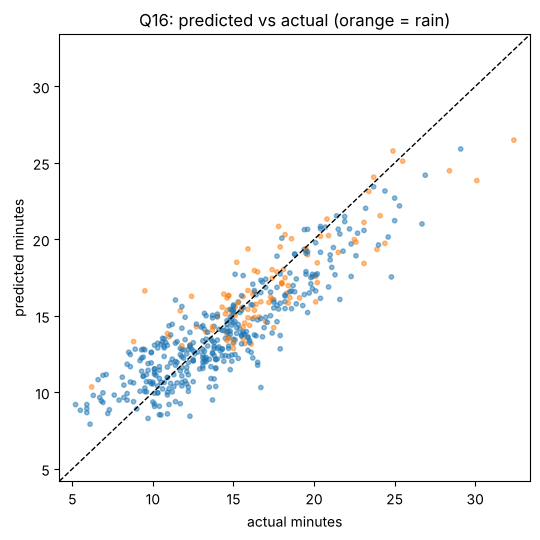

         orders   MAE  mean_actual  mean_pred
rain                                         
no rain     381  1.70        14.20      13.78
rain         98  1.77        17.35      16.98 

            orders   MAE  mean_actual  mean_pred
peak                                            
off-peak       340  1.73        14.59      14.16
peak 18–21     139  1.69        15.48      15.13 

             orders   MAE  mean_actual  mean_pred
actual_band                                      
<10              61  2.40         8.40      10.73
10–15           209  1.29        12.73      12.69
15–20           147  1.71        17.16      15.96
20–25            54  2.32        22.05      19.83
25+               8  3.89        28.05      24.16 

10 worst errors:
          store  order_hour  distance_km  store_queue  raining  actual  pred  abs_err
800    DM-Vashi           9          2.3         11.0        0    24.8  17.5      7.3
2164  DM-Panvel          22          0.4          2.0        1     9.5  16.

In [17]:
res = X_test.assign(actual=y_test, pred=p_tuned, abs_err=(y_test - p_tuned).abs())
lim = [res[['actual', 'pred']].min().min() - 1, res[['actual', 'pred']].max().max() + 1]
plt.figure(figsize=(5.5, 5.5)); plt.scatter(res['actual'], res['pred'], s=10, alpha=.5,
            c=res['raining'].map({0: 'tab:blue', 1: 'tab:orange'}))
plt.plot(lim, lim, 'k--', lw=1); plt.xlim(lim); plt.ylim(lim)
plt.xlabel('actual minutes'); plt.ylabel('predicted minutes'); plt.title('Q16: predicted vs actual (orange = rain)')
plt.tight_layout(); plt.savefig('partB_q16_pred_vs_actual.png', dpi=120); plt.show()
res['rain'] = res['raining'].map({0: 'no rain', 1: 'rain'})
res['peak'] = np.where(res['order_hour'].between(18, 21), 'peak 18–21', 'off-peak')
res['actual_band'] = pd.cut(res['actual'], [0, 10, 15, 20, 25, 60], labels=['<10', '10–15', '15–20', '20–25', '25+'])
for g in ['rain', 'peak', 'actual_band']:
    print(res.groupby(g, observed=True).agg(orders=('abs_err', 'size'), MAE=('abs_err', 'mean'),
          mean_actual=('actual', 'mean'), mean_pred=('pred', 'mean')).round(2), '\n')
print('10 worst errors:'); print(res.nlargest(10, 'abs_err')[['store', 'order_hour', 'distance_km', 'store_queue', 'raining', 'actual', 'pred', 'abs_err']].round(1))

**Q16 — answer / interpretation:** The model's biggest errors are at the **extremes**:

- Very fast orders (< 10 min) are over-predicted by about 2.3 min.
- Very slow ones (25+ min) are under-predicted by about 4 min.

This is the classic KNN regression pattern of pulling toward the middle: an average of neighbours can't be more extreme than the neighbours, and rare far or slow orders have few close neighbours. **Rain vs dry (MAE 1.77 vs 1.70) and peak vs off-peak (1.69 vs 1.73) barely differ**, because rain and hour are features, so the model already adjusts for them. The worst single misses look like one-off events (a 0.4 km rainy order predicted at 16.6 min took 9.5).

## Q17 — Safety buffer

In [18]:
buf = pd.DataFrame({'buffer_min': [0, 1, 2, 3, 4, 5, 6]})
buf['late_share'] = [(y_test > p_tuned + b).mean() for b in buf['buffer_min']]
print(buf.assign(late_share=buf['late_share'].map('{:.1%}'.format)).to_string(index=False))
BUFFER = int(buf.loc[buf['late_share'] <= 0.10, 'buffer_min'].min())
print('Smallest buffer with ≤10% late:', BUFFER, 'min')
cv_pred = np.zeros(len(y_train))                       # robustness check on out-of-fold training predictions
for tr, va in cv.split(X_train):
    cv_pred[va] = tuned.fit(X_train.iloc[tr][CHOSEN], y_train.iloc[tr]).predict(X_train.iloc[va][CHOSEN])
tuned.fit(X_train[CHOSEN], y_train)
print('Out-of-fold late share on TRAIN with that buffer:', f'{(y_train.values > cv_pred + BUFFER).mean():.1%}')

 buffer_min late_share
          0      59.3%
          1      40.5%
          2      21.9%
          3       9.8%
          4       4.4%
          5       1.5%
          6       0.6%
Smallest buffer with ≤10% late: 3 min
Out-of-fold late share on TRAIN with that buffer: 10.9%


**Q17 — answer / interpretation:** **A 3-minute buffer** brings late orders down to **9.8 %**, which meets the ≤ 10 % target.

It only just meets it, though: on out-of-fold training predictions, the same buffer gives 10.9 % late. I'd use 3 min to meet the stated target, but **4 min (4.4 % late)** is the safer production choice if the business prefers a margin over a slightly longer promise.

## Q18 — Predict one order

In [19]:
order = pd.DataFrame([dict(distance_km=2.4, items=12, order_value_rs=1450, store_queue=11, raining=1,
                           rider_experience_months=3, drop_floor=14, order_hour=20)])
order['hour_sin'] = np.sin(2 * np.pi * 20 / 24); order['hour_cos'] = np.cos(2 * np.pi * 20 / 24)
pred18 = tuned.predict(order[CHOSEN])[0]
print(f'Predicted: {pred18:.1f} min → app promise (+{BUFFER} buffer): {int(np.ceil(pred18 + BUFFER))} min')

Predicted: 23.3 min → app promise (+3 buffer): 27 min


**Q18 — answer / interpretation:** The tuned model predicts **23.3 minutes**. With the 3-minute buffer, **the app should promise 27 minutes** (26.3, rounded up). That is much longer than 15 because it's a rush-hour, rainy, high-queue, 2.4 km order going up 14 floors.

## Q19 — The neighbours behind that prediction

In [20]:
dist, ind = tuned[-1].kneighbors(tuned[:-1].transform(order[CHOSEN]))
nb = X_train.iloc[ind[0]][['store', 'order_hour', 'distance_km', 'items', 'store_queue', 'raining', 'rider_experience_months', 'drop_floor']].copy()
nb['actual_min'] = y_train.iloc[ind[0]].values; nb['distance'] = dist[0].round(2)
print(nb.to_string())
print(f"\nNeighbour mean {nb['actual_min'].mean():.1f}, median {nb['actual_min'].median():.1f}, range {nb['actual_min'].min():.1f}–{nb['actual_min'].max():.1f}")
print('Neighbours that were themselves in the rain:', int(nb['raining'].sum()), 'of', len(nb))

            store  order_hour  distance_km  items  store_queue  raining  rider_experience_months  drop_floor  actual_min  distance
1031     DM-Vashi          19         2.64      9         11.0        1                      5.1          23        28.4      1.70
864   DM-Kharghar          18         1.60     10          9.0        1                      5.2          13        21.5      1.76
1580     DM-Nerul          18         1.23     13         11.0        1                     10.5          10        21.2      1.97
1425     DM-Nerul          19         1.77     11         13.0        1                      8.0          25        23.9      2.03
665     DM-Panvel          23         1.69     11          7.0        1                      6.7          23        22.3      2.16
2115  DM-Kharghar          17         2.44     10          7.0        1                     11.5          13        22.7      2.19
739   DM-Kharghar          21         2.84      9         10.0        1            

**Q19 — answer / interpretation:** **Yes, it's a fair summary.** All 8 neighbours are rainy, evening (17:00–23:00) orders with 9–13 items, queues of 7–13, and distances of 1.2–2.8 km. They took **19.0–28.4 minutes (mean 23.1)**, and the 23.3 prediction sits right in that range. One caveat: most neighbours were slightly *closer* than 2.4 km, and the farthest one (2.64 km) was the slowest, so if anything 23.3 is slightly optimistic.

## Q20 — Same order, no rain

In [21]:
dry = order.copy(); dry['raining'] = 0
pred20 = tuned.predict(dry[CHOSEN])[0]
print(f'Rain: {pred18:.1f} min   Dry: {pred20:.1f} min   → rain adds {pred18 - pred20:.1f} min')
print('Data check — mean minutes rain vs dry:', df.groupby('raining')['delivery_minutes'].mean().round(2).to_dict())

Rain: 23.3 min   Dry: 19.7 min   → rain adds 3.6 min
Data check — mean minutes rain vs dry: {0: 13.98, 1: 17.39}


**Q20 — answer / interpretation:** **Rain adds 3.6 minutes** (23.3 → 19.7). That matches the raw data, where rainy orders average 17.4 min against 14.0 dry, a 3.4 min gap. The direction makes business sense: riders go slower on wet roads and rain brings in more orders.

## Q21 — Coupon saving

In [22]:
late_flat = (y_test > 15).mean(); late_model = (y_test > p_tuned + BUFFER).mean()
print(f'Late under flat 15-min promise: {late_flat:.1%}   under model + {BUFFER} min: {late_model:.1%}')
print(f'Per 1,000 orders: coupons {late_flat*1000:.0f} → {late_model*1000:.0f}; saving ≈ ₹{(late_flat - late_model)*1000*50:,.0f}')
print(f'Average promise shown: flat 15.0 vs model {np.mean(np.ceil(p_tuned + BUFFER)):.1f} min')

Late under flat 15-min promise: 43.6%   under model + 3 min: 9.8%
Per 1,000 orders: coupons 436 → 98; saving ≈ ₹16,910
Average promise shown: flat 15.0 vs model 17.9 min


**Q21 — answer / interpretation:** Late orders fall from **43.6 % under the flat 15-minute promise to 9.8 %** with model + 3 min. That is **about 338 fewer coupons per 1,000 orders, or roughly ₹16,900 saved per 1,000 orders**. The trade-off is that the average promise shown rises from 15 to about 17.9 minutes, and some customers may not order once they see a longer time.

## Q22 — Summary table

In [23]:
summary = pd.DataFrame({'median baseline': base, 'raw KNN (k=7)': s_raw, 'scaled KNN (k=7)': s_std,
                        f'tuned KNN (k={K}, {W})': s_tuned, 'tuned, no order_value_rs': r15['tuned, no value']}).T[['MAE', 'RMSE', 'R2']].round(3)
print(summary)

                             MAE   RMSE     R2
median baseline            3.519  4.526 -0.028
raw KNN (k=7)              3.721  4.670 -0.095
scaled KNN (k=7)           1.726  2.165  0.765
tuned KNN (k=8, distance)  1.717  2.150  0.768
tuned, no order_value_rs   1.699  2.150  0.768


**Q22 — answer / interpretation:** Scaling is the step that matters (MAE 3.72 → 1.73). Tuning (→ 1.72) and dropping order_value_rs (→ 1.70) are refinements. The raw model is worse than quoting the median to everyone.

## Q23–Q25 — Written answers

**Q23 — answer / interpretation:** Two features DashMart doesn't collect that would most improve these "similar orders":

1. **Rider wait / rider availability at the store** (time from packed to picked up, or the number of free riders). `store_queue` measures the packing backlog, but an order can sit packed with no rider. The worst misses (e.g. a short 0.4 km order taking 16 min) look like exactly this.
2. **Traffic-aware road travel time** from a maps API, instead of straight-line `distance_km`. 2 km across a highway or through a congested market at 8 PM is not the same trip, and distance is already the strongest predictor, so measuring it better pays off the most.

**Q24 — answer / interpretation:** **KNN advantage:** it picks up interactions without being told about them. Rain hurts more on long trips and big queues slow things down non-linearly. Each prediction is also explainable as "8 orders like yours took about 23 minutes".

**Linear regression advantage:** it gives stable per-unit effects (each extra km adds about X min, each queued order about Y) that the ops team can read and plan around, and it can **extrapolate**.

**For a brand-new fifth store, I'd trust linear regression more at first.** A new location may have conditions outside the existing data (longer distances, taller buildings), and KNN can't predict beyond what its neighbours did: a 6 km order would get the average of the 4–5 km orders. Switch to KNN once the new store has a few hundred orders of its own.

**Q25 — answer / interpretation:** **Executive summary:** The new ETA predicts each order's delivery time to within **1.7 minutes on average** (MAE), comfortably beating the 2.5-minute target, against a 3.5-minute error for a flat estimate. Showing customers **prediction + 3 minutes** cuts late orders from **43.6 % to 9.8 %**, which meets the ≤ 10 % target, though only just. A 4-minute buffer (4.4 % late) gives more margin.

At ₹50 per apology coupon, that saves roughly **₹16,900 per 1,000 orders**. The cost is that the average promise rises from 15 to about 18 minutes.

Distance, store queue and rain drive most of the estimate. Basket value adds nothing, so I dropped it.

**Main limitation:** it is weakest on unusually fast or slow orders, and it can only reproduce conditions seen in the past month. Retrain it monthly, and don't rely on it for a new store or monsoon peaks until there is local data.